# Qiskit 101: from a circuit to a quantum computer
**Qiskit Fall Fest 2026 · University of Stuttgart**

- Level: beginner
- QPU time: a few seconds

In this notebook we walk through the **Qiskit pattern**, the four steps of every quantum program:

| Step | What happens | Section |
|---|---|---|
| **Map** | write the problem as a quantum circuit | [3](#map) |
| **Optimize** | transpile the circuit for a real chip | [4](#optimize) |
| **Execute** | run it with a Qiskit Runtime primitive | [5](#execute) |
| **Post-process** | turn the measured bitstrings into an answer | [6](#post-process) |

Along the way we build an entangled three-qubit state, the GHZ or "cat" state, and run it on a real IBM quantum computer.

There are two versions of this notebook: **the hands-on version**, with short exercises marked ✏️ where you replace `...` with your own code, and **the solutions version**, with everything filled in. Sections 1 and 2 (installing Qiskit and setting up your account) only need to be done once.

## 1. Set up Qiskit

[**Qiskit**](https://www.ibm.com/quantum/qiskit) is IBM's open-source software development kit for quantum computing. With the Qiskit SDK you build and optimize quantum circuits; with **Qiskit Runtime** (`qiskit-ibm-runtime`) you send them to IBM's quantum computers through the cloud. **Qiskit Aer** (`qiskit-aer`) simulates circuits on your laptop.

You need Python 3.10 or newer. Run the next cell once to install the three packages (the same versions as in the Fall Fest hackathon), then restart the kernel if Jupyter asks you to.

In [ ]:
%pip install "qiskit[visualization]==2.6.1" "qiskit-ibm-runtime==0.51.0" "qiskit-aer==0.18.0"

In [1]:
import qiskit

print(f"Qiskit version: {qiskit.__version__}")

Qiskit version: 2.6.2


### Troubleshooting

If the previous cell raised an error, you can opt to install Qiskit in a virtual environment (two suggested methods follow). If you have no errors, you can ignore this cell and proceed to the next one.

Here we propose two different methods to set up a virtual environment to install Qiskit.
1. Using [venv](https://docs.python.org/3/library/venv.html), as explained in the [Qiskit installation guide](https://docs.quantum.ibm.com/guides/install-qiskit). 
2. Using [conda](https://docs.conda.io/projects/conda/en/latest/user-guide/install/index.html), as explained in this video of [Coding with Qiskit](https://www.youtube.com/watch?v=93-zLTppFZw&list=PLOFEBzvs-VvrgHZt3exM_NNiNKtZlHvZi&index=4).

## 2. Set up your IBM Cloud account <a id="setting-ibm-cloud"></a>

To use a real quantum computer, you need an `api key` - a main entrance ticket to the cloud and a `crn` - token that will bring your resources to you by setting your account.

Set up your account as follows:

1. Go to the [IBM Quantum&reg; Platform](https://quantum.cloud.ibm.com/).
2. Go to the top right corner (as shown in the above picture), create your API token, and copy it to a secure location.
3. In the next cell, replace `deleteThisAndPasteYourAPIKeyHere` with your API key.
4. Go to the bottom left corner (as shown in the above picture) and **create your instance**. Make sure to choose the open plan.
5. After the instance is created, copy its associated CRN code. You may need to refresh to see the instance.
6. In the cell below, replace `deleteThisAndPasteYourCRNHere` with your CRN code.

See [this guide](https://quantum.cloud.ibm.com/docs/guides/cloud-setup) for more details on how to set up your IBM Cloud&reg; account.

<div class="alert alert-block alert-warning">
    
⚠️ **Note:** Treat your API key as you would a secure password. See the [Cloud setup](https://quantum.cloud.ibm.com/docs/guides/cloud-setup#cloud-save) guide for more information about using your API key in both secure and untrusted environments.

Additionally, if you are a member of the IBM partner network university, please use your institution's email address for your IBM ID to receive the partner benefit. 
</div>


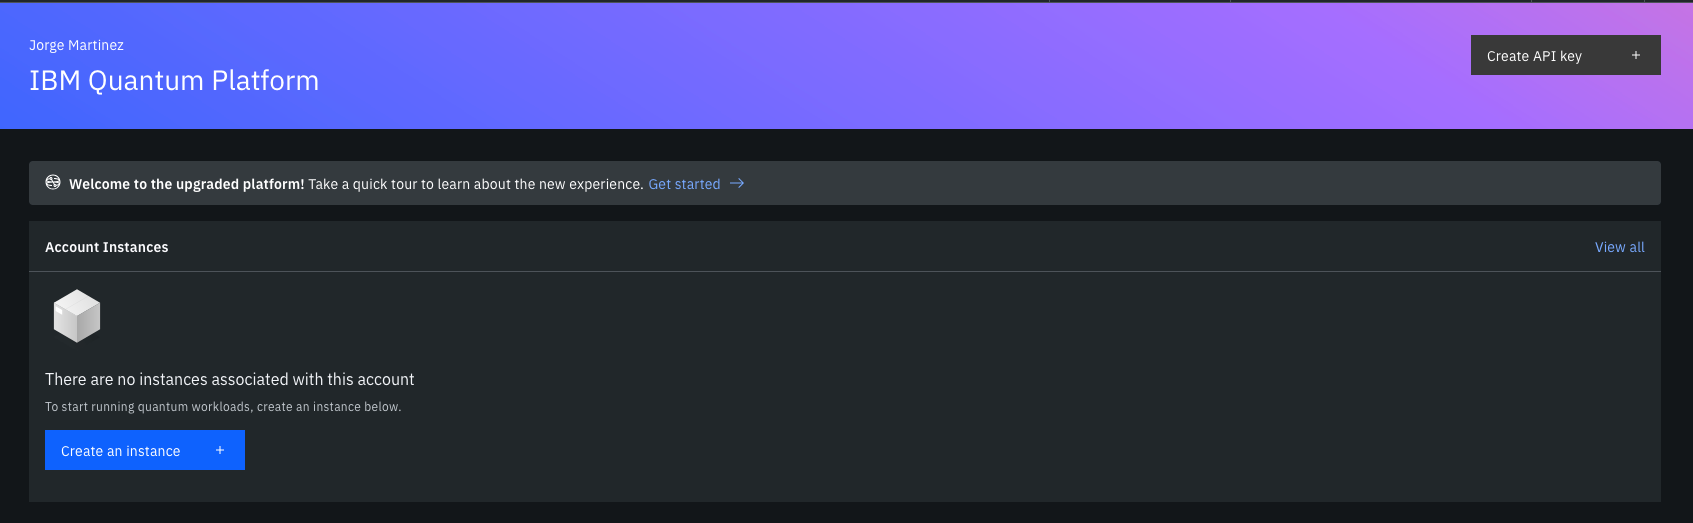




In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Save your API key and crn and have access to the quantum computers
your_api_key = "deleteThisAndPasteYourAPIKeyHere"
your_crn = "deleteThisAndPasteYourCRNHere"

QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token=your_api_key,
    instance=your_crn,
    overwrite=True
)

<div class="alert alert-block alert-info">

After the cell above has run once, your key is stored on your computer (in `~/.qiskit/qiskit-ibm.json`) and you never need to paste it again. **Delete your key and CRN from the cell** before you save or share this notebook. In the next sections, `QiskitRuntimeService()` loads the saved account by itself.
</div>

In [3]:
# Check that the account works: list the quantum computers you can use
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
[backend.name for backend in service.backends()]

['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']

<a id="map"></a>
## 3. Map: build quantum circuits

A **quantum circuit** is a list of instructions for a set of qubits. Every qubit starts in the state $|0\rangle$, **gates** change the state, and **measurements** read out a 0 or a 1 at the end.

### 3.1 One qubit
Let's start with one qubit and a single **Hadamard** gate, which puts the qubit in an equal superposition of 0 and 1.

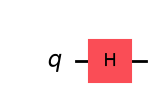

In [4]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.h(0)          # Hadamard gate on qubit 0
qc.draw("mpl")

Before running anything on hardware, we can compute the **exact state** that the circuit prepares with `Statevector`, and draw it on the **Bloch sphere**.

Any single-qubit state can be written with two angles,
$$
|\psi\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle ,
$$
and those two angles are a point on a sphere: $\theta$ is measured down from the north pole, $\varphi$ around the equator, starting from the $x$ axis.

| State | $\theta$ | $\varphi$ | On the Bloch sphere |
|---|---|---|---|
| $\vert 0\rangle$ | $0$ | (any) | north pole |
| $\vert 1\rangle$ | $\pi$ | (any) | south pole |
| $\vert +\rangle = \frac{\vert 0\rangle + \vert 1\rangle}{\sqrt 2}$ | $\pi/2$ | $0$ | equator, along $+x$ |
| $\vert -\rangle = \frac{\vert 0\rangle - \vert 1\rangle}{\sqrt 2}$ | $\pi/2$ | $\pi$ | equator, along $-x$ |

$|+\rangle$ has equal weights, $\cos\frac{\theta}{2} = \sin\frac{\theta}{2} = \frac{1}{\sqrt 2}$, so $\theta = \pi/2$ puts it on the equator, and the relative phase $e^{i\varphi} = +1$ gives $\varphi = 0$, which points it along $+x$. The probability of measuring 1 is $\sin^2\frac{\theta}{2}$, so every state on the equator gives 0 and 1 half the time each; they differ only in the phase $\varphi$.

<IPython.core.display.Latex object>

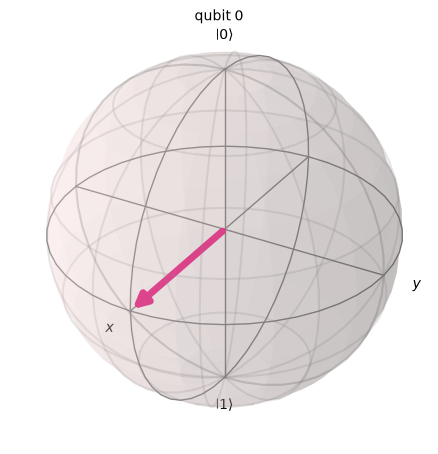

In [5]:
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

state = Statevector(qc)
display(state.draw("latex"))
plot_bloch_multivector(state)

The gates you'll need today:

| Code | Gate | What it does |
|---|---|---|
| `qc.x(q)` | X (NOT) | flips $\vert 0\rangle \leftrightarrow \vert 1\rangle$ |
| `qc.h(q)` | Hadamard | $\vert 0\rangle \to \vert +\rangle = \frac{\vert 0\rangle + \vert 1\rangle}{\sqrt 2}$, $\;\vert 1\rangle \to \vert -\rangle = \frac{\vert 0\rangle - \vert 1\rangle}{\sqrt 2}$ |
| `qc.z(q)` | Z | flips the sign of $\vert 1\rangle$ (a phase flip) |
| `qc.cx(c, t)` | CNOT | flips qubit `t` if qubit `c` is $\vert 1\rangle$ |

#### ✏️ Exercise 1
Prepare the state $|-\rangle = \frac{1}{\sqrt 2}\left(|0\rangle - |1\rangle\right)$. On the Bloch sphere it points the opposite way from $|+\rangle$.

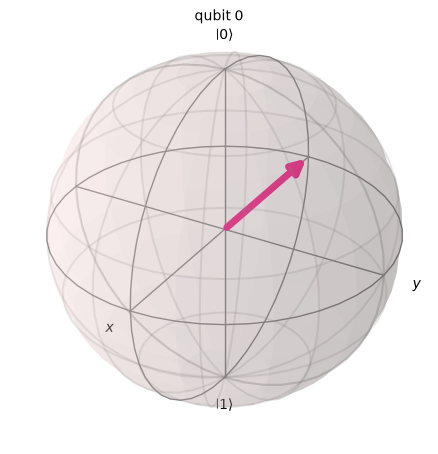

In [8]:
qc_minus = QuantumCircuit(1)
# ✏️ Exercise 1: add the gates that prepare |−⟩
qc_minus.x(0)
qc_minus.h(0)

plot_bloch_multivector(Statevector(qc_minus))

### 3.2 Two qubits: entanglement
A Hadamard followed by a CNOT creates a **Bell state**, $\frac{1}{\sqrt 2}\left(|00\rangle + |11\rangle\right)$: both qubits are 0 or both are 1, but which one is decided only when you measure.

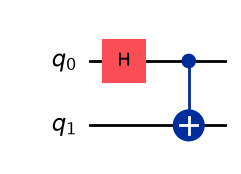

<IPython.core.display.Latex object>

In [9]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
display(bell.draw("mpl"))
Statevector(bell).draw("latex")

The Bloch sphere shows each qubit on its own. For an entangled state that fails: neither qubit has a state of its own, so both arrows shrink to nothing. The information sits in the correlation between them, which the measurement probabilities show:

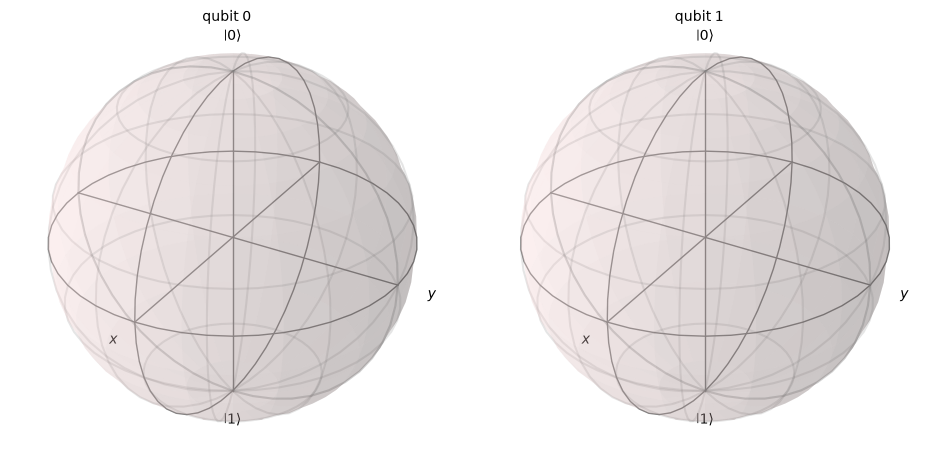

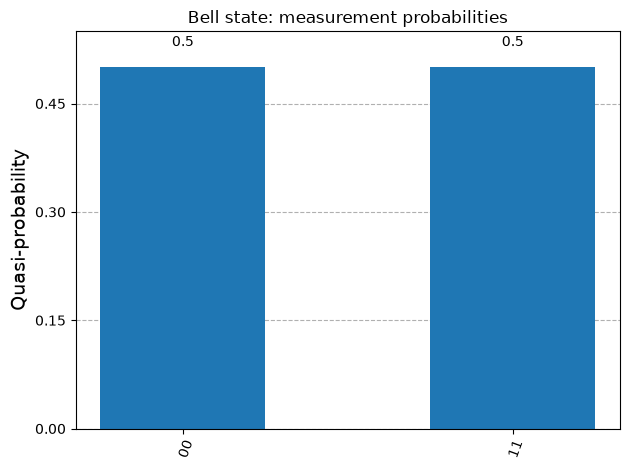

In [10]:
from qiskit.visualization import plot_histogram

display(plot_bloch_multivector(Statevector(bell)))
plot_histogram(Statevector(bell).probabilities_dict(), title="Bell state: measurement probabilities")

### 3.3 Three qubits: a cat state
Extend the idea to three qubits: the **GHZ state** $\frac{1}{\sqrt 2}\left(|000\rangle + |111\rangle\right)$, also called a cat state, since all qubits are 0 and 1 at the same time, like Schrödinger's cat. (It's also the star of this afternoon's hackathon, *Herding Quantum Cats*.)

#### ✏️ Exercise 2
Build the three-qubit GHZ state. Hint: start from the Bell circuit and entangle one more qubit.

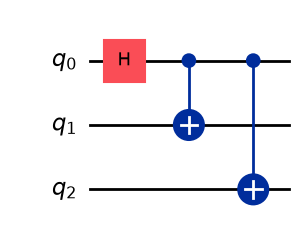

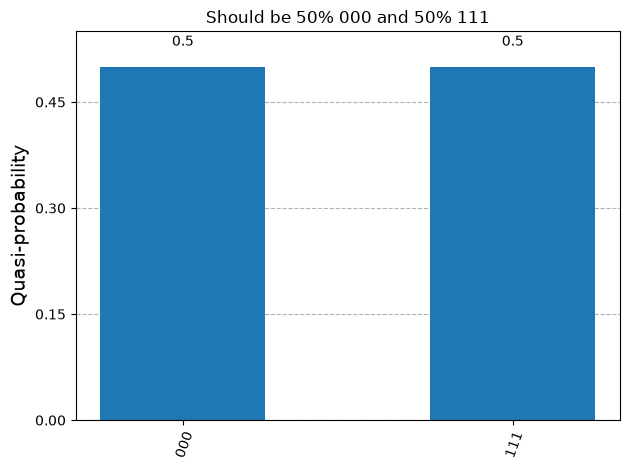

In [11]:
ghz = QuantumCircuit(3)
# ✏️ Exercise 2: add the gates that prepare (|000⟩ + |111⟩)/√2
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(0, 2)

display(ghz.draw("mpl"))
plot_histogram(Statevector(ghz).probabilities_dict(), title="Should be 50% 000 and 50% 111")

A real quantum computer can't give us the state vector, only measurement results. So we add a measurement on every qubit. `measure_all` also creates a classical register called `meas` to store the results.

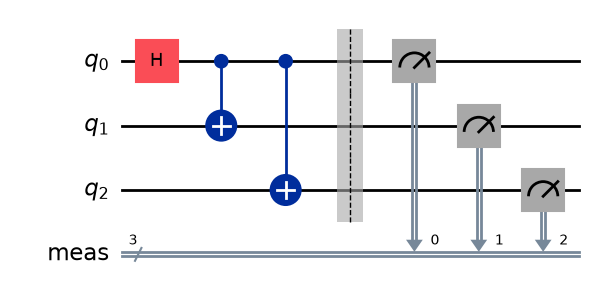

In [12]:
ghz.measure_all()
ghz.draw("mpl")

<a id="optimize"></a>
## 4. Optimize: transpile for a real chip

Our circuit is written for ideal qubits. A real chip has its own **native gates** (on IBM's Heron chips: `cz`, `rz`, `sx`, `x`) and two-qubit gates only work between **neighbouring qubits**. The **transpiler** rewrites the circuit so that the chip can run it: it chooses which physical qubits to use, adds swaps if needed, translates every gate into native gates and simplifies the result.

First, choose the computer. `least_busy` picks the one with the shortest queue. If you don't have an account, or the queues are long, set `USE_REAL_HARDWARE = False` to use a local simulation of `ibm_kingston`, which includes its noise.

In [13]:
USE_REAL_HARDWARE = True

if USE_REAL_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, min_num_qubits=3)
else:
    from qiskit_ibm_runtime.fake_provider import FakeKingston
    backend = FakeKingston()        # local copy of ibm_kingston, noise included

print(f"Backend: {backend.name}, {backend.num_qubits} qubits, native gates: {sorted(backend.operation_names)}")

Backend: ibm_marrakesh, 156 qubits, native gates: ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'measure_reset', 'measure_reset_2', 'reset', 'reset_2', 'rz', 'sx', 'x', 'xslow']


A **pass manager** runs the transpiler passes. `generate_preset_pass_manager` gives you a ready-made one; `optimization_level` goes from 0 (just make it run) to 3 (try hardest to make the circuit short).

#### ✏️ Exercise 3
Create a pass manager with `optimization_level=3` for our `backend`, and use it to transpile `ghz`.

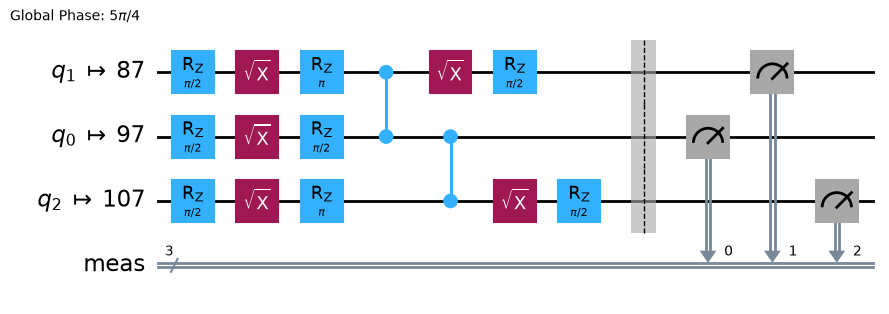

In [15]:
from qiskit.transpiler import generate_preset_pass_manager

# ✏️ Exercise 3: create the pass manager and transpile the GHZ circuit
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_ghz = pm.run(ghz)

isa_ghz.draw("mpl", idle_wires=False)

The result is an **ISA circuit** (written in the chip's *instruction set architecture*). Our two CNOTs became CZ gates surrounded by single-qubit rotations, and our virtual qubits 0, 1, 2 now live on three neighbouring physical qubits of the chip:

In [16]:
print("Before:", dict(ghz.count_ops()))
print("After: ", dict(isa_ghz.count_ops()))
print("Physical qubits used:", isa_ghz.layout.final_index_layout())

Before: {'measure': 3, 'cx': 2, 'h': 1, 'barrier': 1}
After:  {'rz': 8, 'sx': 5, 'measure': 3, 'cz': 2, 'barrier': 1}
Physical qubits used: [97, 87, 107]


<a id="execute"></a>
## 5. Execute: run with a Qiskit Runtime primitive

Qiskit Runtime runs circuits through two **primitives**:
- **Sampler**: runs circuits and returns the measured bitstrings (what we want here);
- **Estimator**: returns expectation values of observables, such as an energy ([guide](https://quantum.cloud.ibm.com/docs/en/guides/primitives)).

A job takes a list of **PUBs** (primitive unified blocs). A Sampler PUB is a circuit, optionally with parameter values and a number of shots; here it's just our circuit, run with 1000 shots. (An Estimator PUB must also contain the observables whose expectation values you want, `(circuit, observables)`, optionally with parameter values and a target precision.)

We use the new client-side Sampler from `qiskit_ibm_runtime.executor_sampler`, which is built on IBM's new **Executor** primitive. The older `SamplerV2` still works but has been deprecated since qiskit-ibm-runtime 0.50.

#### ✏️ Exercise 4
Create a `Sampler` for our `backend` and run `isa_ghz` with 1000 shots.

In [18]:
from qiskit_ibm_runtime.executor_sampler import Sampler

# ✏️ Exercise 4: create the sampler and submit the job
sampler = Sampler(mode = backend)
job = sampler.run([isa_ghz], shots=1000)

print("Job ID:", job.job_id())
job.status()

Job ID: dboqjm0ou4as73csh8bg


'QUEUED'

On real hardware the job first waits in a queue. You can close the notebook and pick the job up later with its ID; the IBM Quantum Platform website lists your jobs too. `job.result()` waits until the job is done.

In [20]:
# job = service.job("PASTE-A-JOB-ID-HERE")   # pick up a job you submitted earlier
result = job.result()

<a id="post-process"></a>
## 6. Post-process: from bitstrings to an answer

The result has one entry per PUB. The counts are stored under the name of the classical register, `meas`:

{'111': 447, '000': 525, '011': 9, '010': 9, '110': 2, '100': 3, '101': 5}


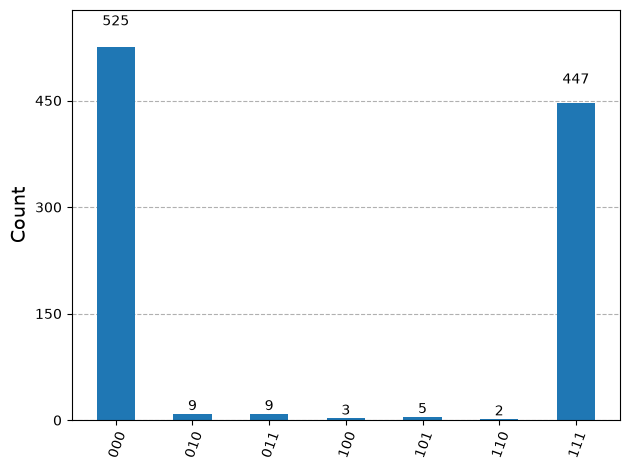

In [21]:
counts = result[0].data.meas.get_counts()
print(counts)
plot_histogram(counts)

To see what the noise did, compare with an ideal, noise-free run. Qiskit's `StatevectorSampler` runs the original circuit exactly, on your laptop:

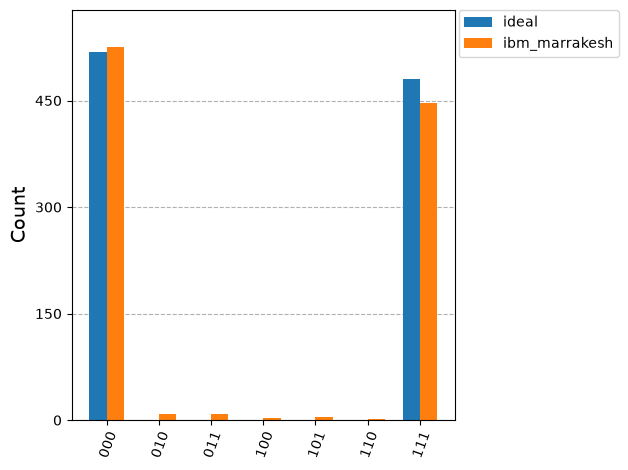

In [22]:
from qiskit.primitives import StatevectorSampler

ideal_counts = StatevectorSampler().run([ghz], shots=1000).result()[0].data.meas.get_counts()
plot_histogram([ideal_counts, counts], legend=["ideal", backend.name], bar_labels=False)

#### ✏️ Exercise 5
A perfect GHZ state only ever gives `000` or `111`. What fraction of your shots did?

In [23]:
# ✏️ Exercise 5: fraction of shots that gave 000 or 111
shots = sum(counts.values())
p_good = (counts["000"] + counts["111"]) / shots

print(f"{p_good:.1%} of the shots are 000 or 111")

97.2% of the shots are 000 or 111


On a perfect computer this would be 100%; the rest is noise. Even 100% wouldn't prove that the qubits are entangled, though: a classical coin that sets all three bits to 0 or all to 1 would score the same. How to prove entanglement, and how to keep a cat clean when it has 12 or 100 qubits instead of 3, is exactly what the hackathon is about.

## 7. Where to go next
- [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning): free courses, starting with *Basics of quantum information*
- [Qiskit documentation](https://quantum.cloud.ibm.com/docs/en/guides): guides for every step of the Qiskit pattern
- [IBM Quantum Composer](https://quantum.cloud.ibm.com/composer): build circuits by drag and drop
- [Error mitigation and suppression](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques): how to fight the noise you just saw

In [24]:
import qiskit, qiskit_ibm_runtime, qiskit_aer

print("Qiskit:", qiskit.__version__)
print("Qiskit Runtime:", qiskit_ibm_runtime.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)

Qiskit: 2.6.2
Qiskit Runtime: 0.51.0
Qiskit Aer: 0.18.0


---
Prepared by Afonso Azenha for Qiskit Fall Fest 2026 at the University of Stuttgart.

Sections 1 and 2 (installation and account setup, including the screenshot and the `save_account` cell) are adapted from IBM's *First Step into Quantum Computing* hands-on notebook, created by Sophy Shin and reviewed by Nate Earnest-Noble. The rest of the notebook was rewritten for this event.

<div class="alert alert-info">

© IBM Corp., 2025. Modified in 2026 (see above).

This is licensed under the Apache License, Version 2.0. You may obtain a copy of this license at http://www.apache.org/licenses/LICENSE-2.0.

Any modifications or derivative works of this must retain this copyright notice, and modified files need to carry a notice indicating that they have been altered from the originals.
</div>